# lab 5: stable diffusion în practică

scopul lucrării: să vedem cum schimbă setările unui model text-imagine calitatea, potrivirea cu textul și timpul.

regula principală: schimbăm **un singur parametru o dată** și păstrăm aceleași seed-uri. altfel nu știm ce a produs diferența.

## sarcina 1. pregătirea

instalăm bibliotecile. în colab rulăm celula o singură dată.

In [1]:
%pip install -q diffusers transformers accelerate

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from diffusers import (StableDiffusionPipeline, StableDiffusionImg2ImgPipeline,
                       DDIMScheduler, DPMSolverMultistepScheduler, EulerDiscreteScheduler)
from transformers import CLIPModel, CLIPProcessor

torch.manual_seed(42)

încărcăm stable diffusion 1.5 în float16 pe gpu. descărcarea durează câteva minute.

In [3]:
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
pipe.set_progress_bar_config(disable=True)
pipe.enable_attention_slicing()     # uses less gpu memory
base_scheduler = pipe.scheduler     # default sampler, we keep it to restore later
print(type(base_scheduler).__name__)

D:\pr\PycharmProjects\slm_llm\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

PNDMScheduler


cele 3 prompturi și cele 3 seed-uri. configurația de bază are 30 de pași, ghidare 7.5 și 512×512.

In [4]:
PROMPTS = ["a watercolor painting of a red fox in a snowy forest",
           "a photo of a modern library interior, natural light",
           "a cartoon robot reading a book, flat illustration"]
SEEDS = [42, 7, 123]

BASE = {"steps": 30, "guidance": 7.5, "scheduler": None, "negative": None,
        "prompts": PROMPTS, "seeds": SEEDS}

## sarcina 2. instrumentele de măsurare

**scorul clip** arată cât de bine se potrivește imaginea cu textul. mai mare înseamnă mai bine.

formula este aceeași ca la `clip_score` din torchmetrics: 100 × similaritatea cosinus dintre vectorul imaginii și vectorul textului, iar dacă iese negativ punem 0. folosim același model `openai/clip-vit-base-patch16`. funcția din torchmetrics nu merge cu versiunea nouă a bibliotecii transformers (5.x), de aceea scriem calculul direct. în plus, așa încărcăm modelul clip o singură dată.

**timpul** îl măsurăm cu `time.perf_counter`. înainte de fiecare citire așteptăm ca gpu să termine.

In [5]:
CLIP = "openai/clip-vit-base-patch16"
clip_model = CLIPModel.from_pretrained(CLIP).eval()     # on cpu, gpu stays for sd
clip_proc = CLIPProcessor.from_pretrained(CLIP)

def clip_one(img, text):
    inp = clip_proc(text=[text], images=img, return_tensors="pt", padding=True)
    with torch.no_grad():
        out = clip_model(**inp)
    img_vec = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    txt_vec = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return max(100 * (img_vec * txt_vec).sum().item(), 0)   # same as torchmetrics clip_score

def generate(cfg, prompt, seed):
    g = torch.Generator("cuda").manual_seed(seed)
    return pipe(prompt, num_inference_steps=cfg["steps"], guidance_scale=cfg["guidance"],
                negative_prompt=cfg["negative"], height=512, width=512, generator=g).images[0]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

funcția `ruleaza` generează toate imaginile pentru o configurație. ea întoarce scorul clip mediu, abaterea standard, timpul mediu pe imagine și imaginile.

In [6]:
def ruleaza(config):
    cfg = {**BASE, **config}                       # start from base, change only what we ask
    pipe.scheduler = base_scheduler
    if cfg["scheduler"] is not None:
        pipe.scheduler = cfg["scheduler"].from_config(base_scheduler.config)
    imgs, scores, times = [], [], []
    for prompt in cfg["prompts"]:
        for seed in cfg["seeds"]:
            torch.cuda.synchronize()
            start = time.perf_counter()
            img = generate(cfg, prompt, seed)
            torch.cuda.synchronize()
            times.append(time.perf_counter() - start)
            imgs.append(img)
            scores.append(clip_one(img, prompt))
    pipe.scheduler = base_scheduler
    return {"clip": np.mean(scores), "std": np.std(scores), "time": np.mean(times),
            "imgs": imgs, "scores": scores}

def show(imgs, ncol, title):
    nrow = (len(imgs) + ncol - 1) // ncol
    plt.figure(figsize=(2.5 * ncol, 2.5 * nrow))
    for i, img in enumerate(imgs):
        plt.subplot(nrow, ncol, i + 1)
        plt.imshow(img)
        plt.axis("off")
    plt.suptitle(title)
    plt.show()

all_results = {}

def report(name, r):
    all_results[name] = r
    print(f"{name}: clip {r['clip']:.2f} ± {r['std']:.2f}, timp {r['time']:.2f} s / imagine")

prima generare este mai lentă (încălzire). o facem o dată și nu o măsurăm.

In [7]:
_ = generate(BASE, "a cat", 0)

### imaginile de bază

9 imagini: 3 prompturi × 3 seed-uri. pe fiecare rând este un prompt.

bază: clip 34.60 ± 1.56, timp 13.60 s / imagine


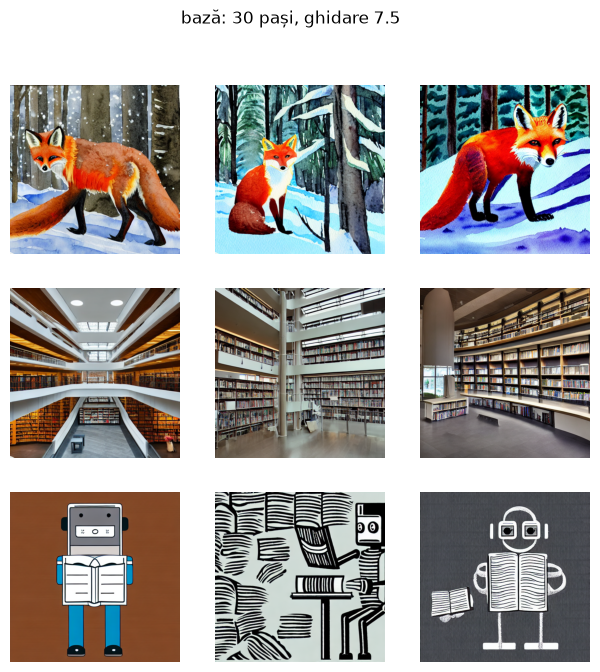

In [8]:
base = ruleaza({})
report("bază", base)
show(base["imgs"], 3, "bază: 30 pași, ghidare 7.5")

## sarcina 3. experimentele

### a. scara de ghidare

ghidarea spune cât de tare ascultă modelul de prompt.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


A ghidare 1: clip 26.86 ± 5.31, timp 7.77 s / imagine


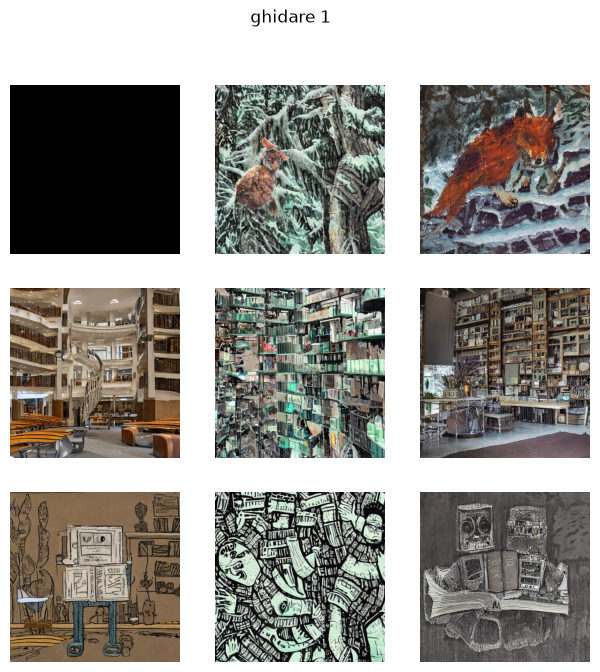

A ghidare 3: clip 34.29 ± 2.48, timp 13.65 s / imagine


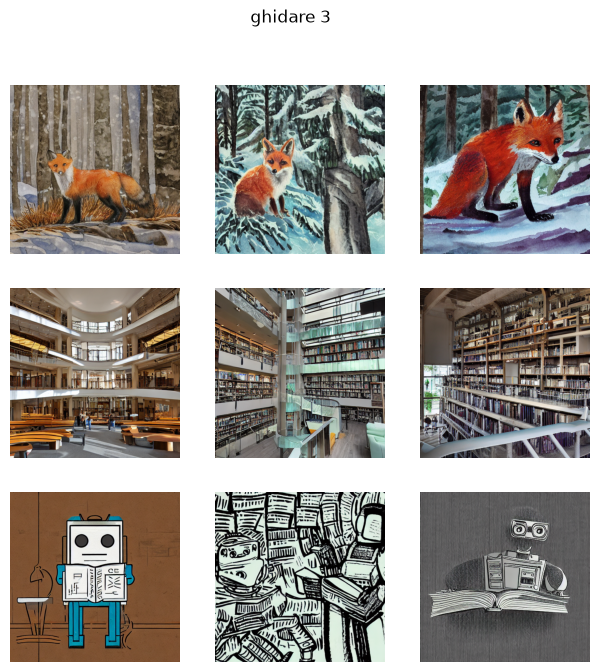

A ghidare 7.5: clip 34.60 ± 1.56, timp 13.52 s / imagine


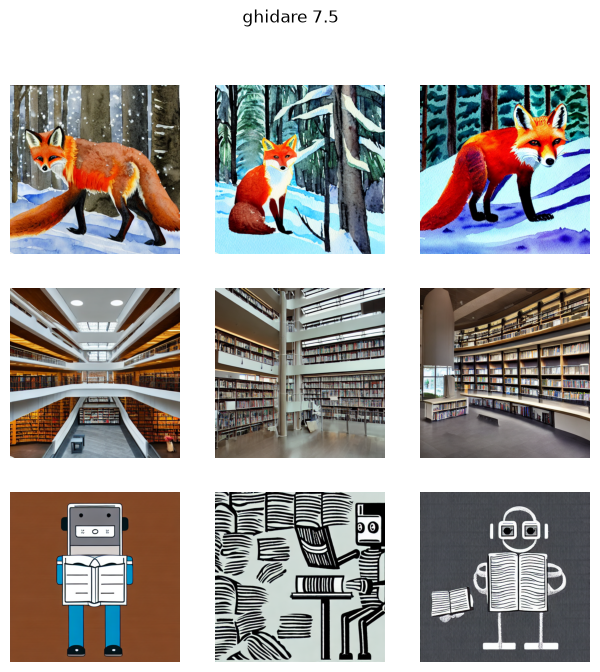

A ghidare 12: clip 34.16 ± 1.74, timp 13.51 s / imagine


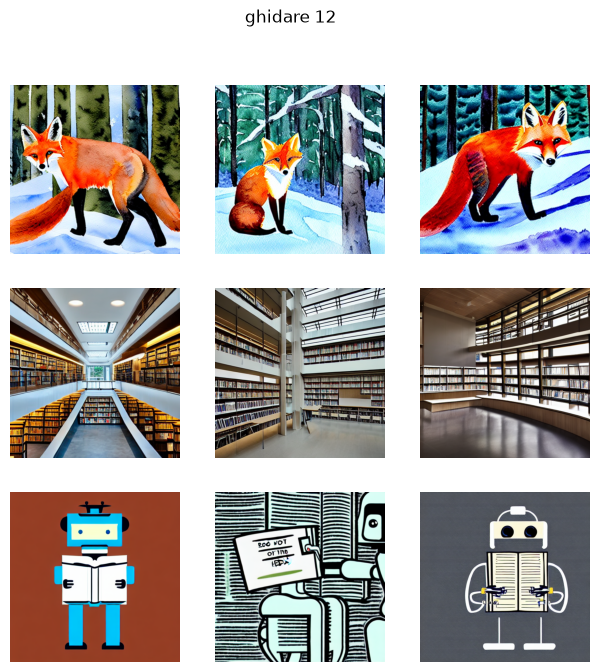

A ghidare 20: clip 33.19 ± 3.40, timp 13.50 s / imagine


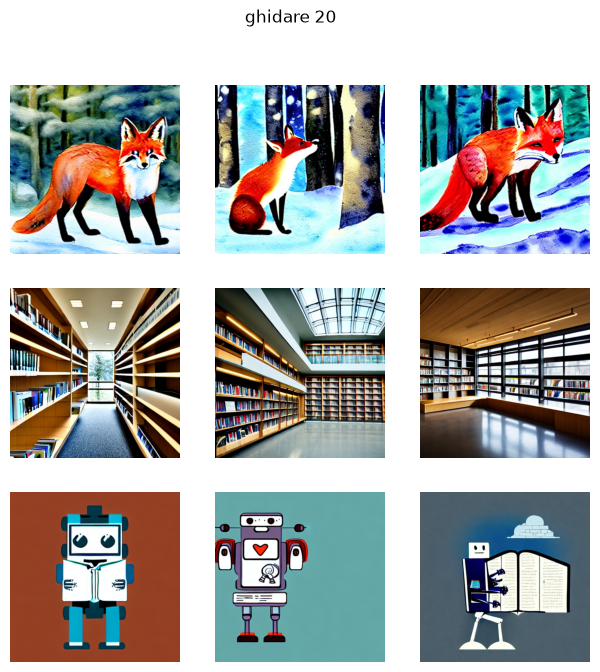

In [9]:
res_a = {}
for gs in [1, 3, 7.5, 12, 20]:
    res_a[gs] = ruleaza({"guidance": gs})
    report(f"A ghidare {gs}", res_a[gs])
    show(res_a[gs]["imgs"], 3, f"ghidare {gs}")

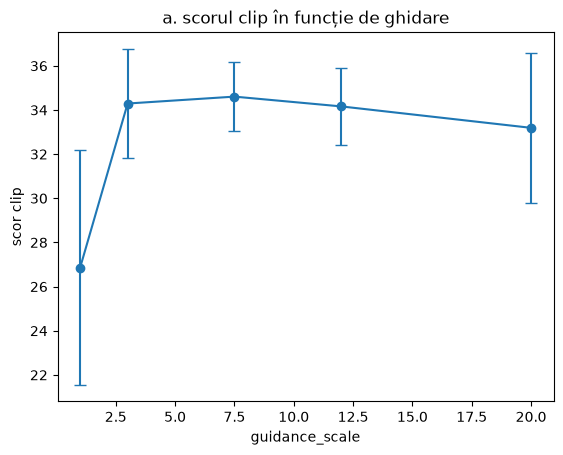

In [10]:
xs = list(res_a)
plt.errorbar(xs, [res_a[k]["clip"] for k in xs], yerr=[res_a[k]["std"] for k in xs],
             marker="o", capsize=4)
plt.xlabel("guidance_scale")
plt.ylabel("scor clip")
plt.title("a. scorul clip în funcție de ghidare")
plt.show()

### b. numărul de pași

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


B 5 pași: clip 29.81 ± 6.98, timp 3.02 s / imagine


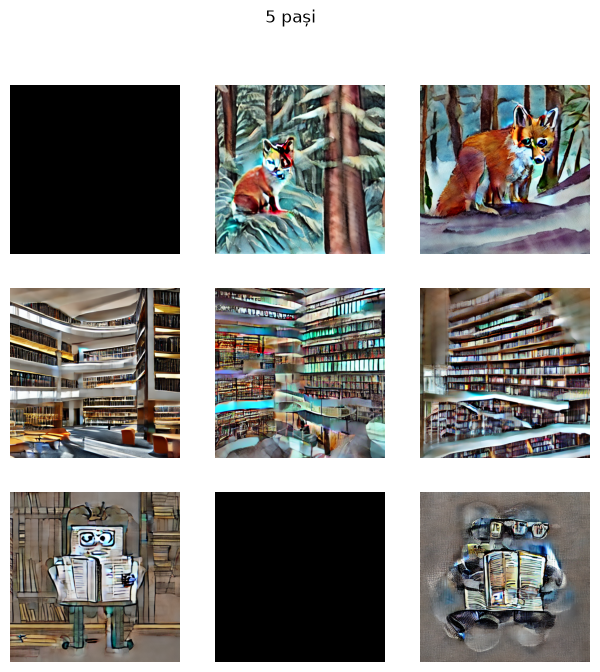

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


B 10 pași: clip 31.19 ± 5.70, timp 5.11 s / imagine


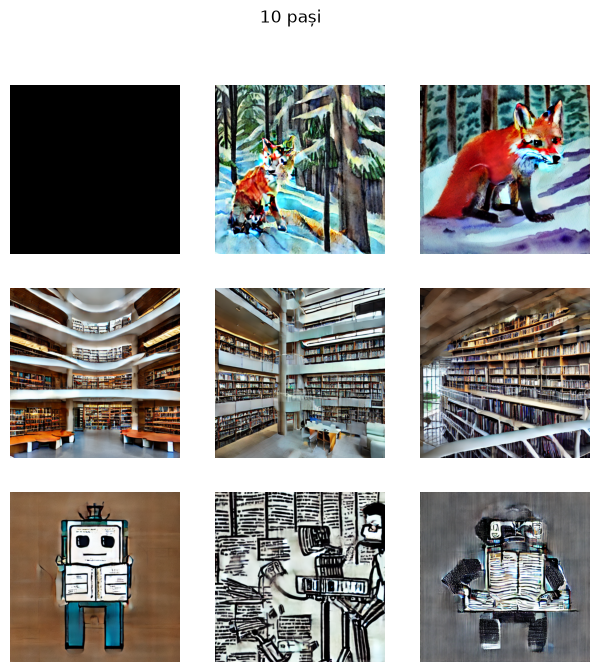

B 20 pași: clip 34.84 ± 1.78, timp 9.31 s / imagine


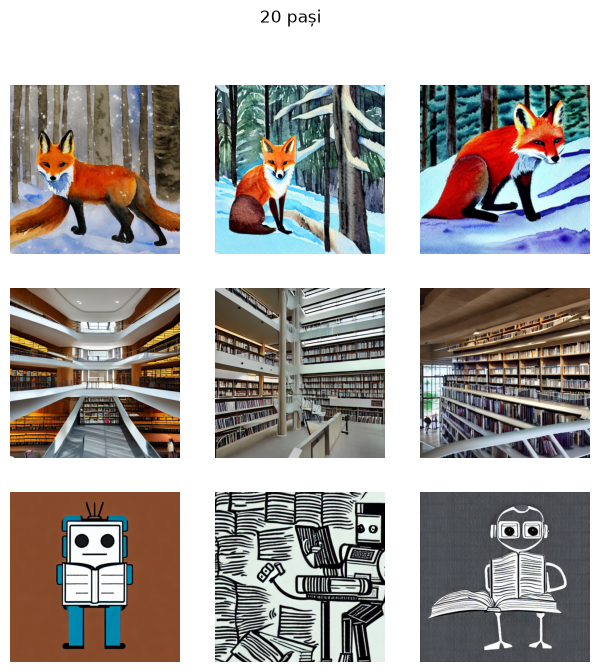

B 50 pași: clip 34.43 ± 1.73, timp 21.90 s / imagine


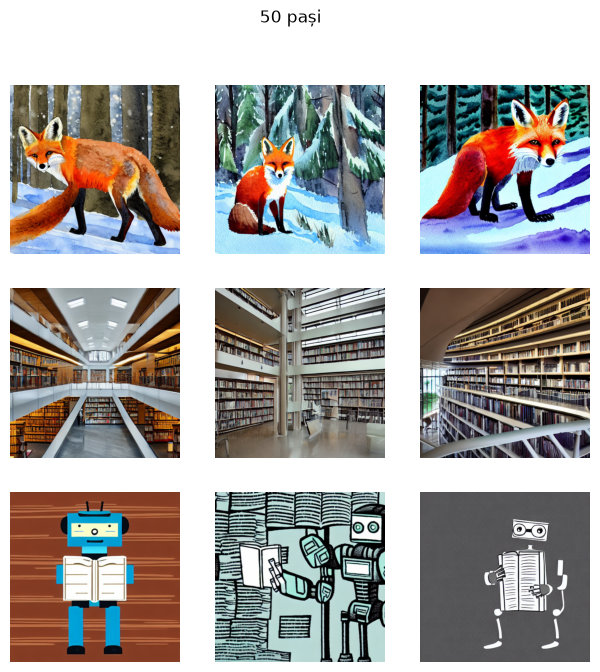

In [11]:
res_b = {}
for n in [5, 10, 20, 50]:
    res_b[n] = ruleaza({"steps": n})
    report(f"B {n} pași", res_b[n])
    show(res_b[n]["imgs"], 3, f"{n} pași")

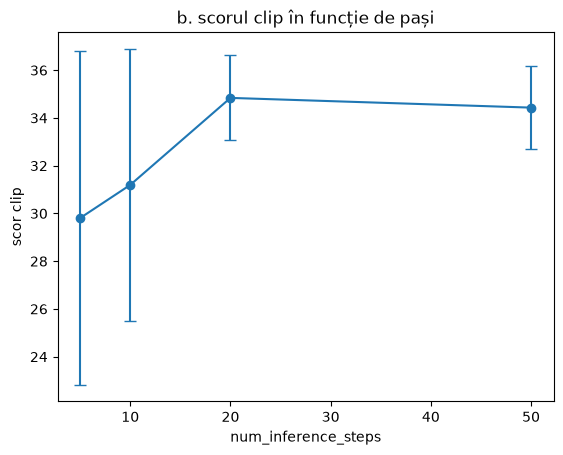

In [12]:
xs = list(res_b)
plt.errorbar(xs, [res_b[k]["clip"] for k in xs], yerr=[res_b[k]["std"] for k in xs],
             marker="o", capsize=4)
plt.xlabel("num_inference_steps")
plt.ylabel("scor clip")
plt.title("b. scorul clip în funcție de pași")
plt.show()

### c. metoda de eșantionare

încercăm ddim, dpm-solver și euler, fiecare la 10 și la 30 de pași.

C DDIM 10 pași: clip 34.24 ± 1.87, timp 4.69 s / imagine


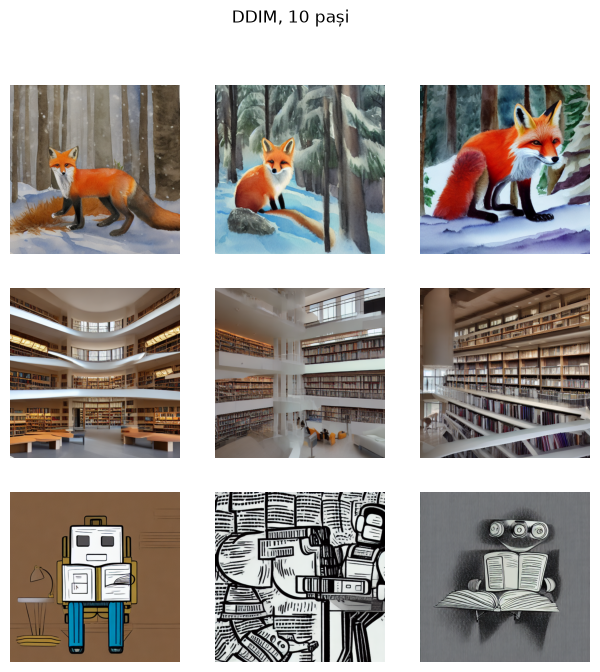

C DDIM 30 pași: clip 35.03 ± 2.03, timp 13.07 s / imagine


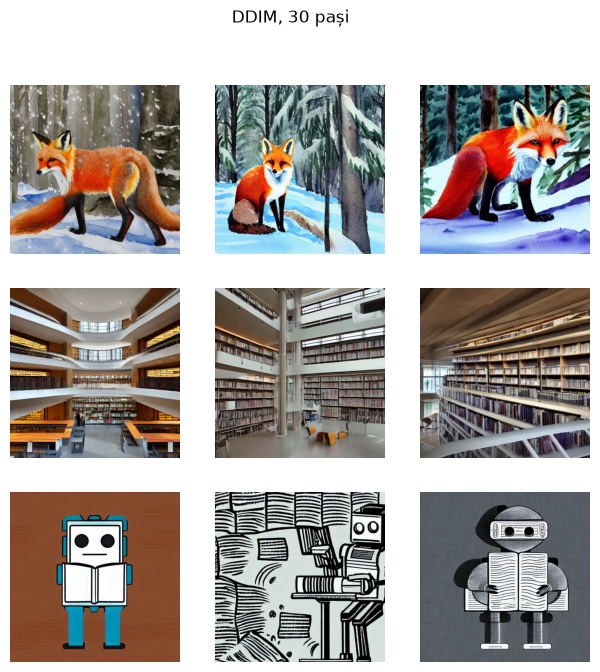

C DPM-Solver 10 pași: clip 34.96 ± 1.86, timp 4.65 s / imagine


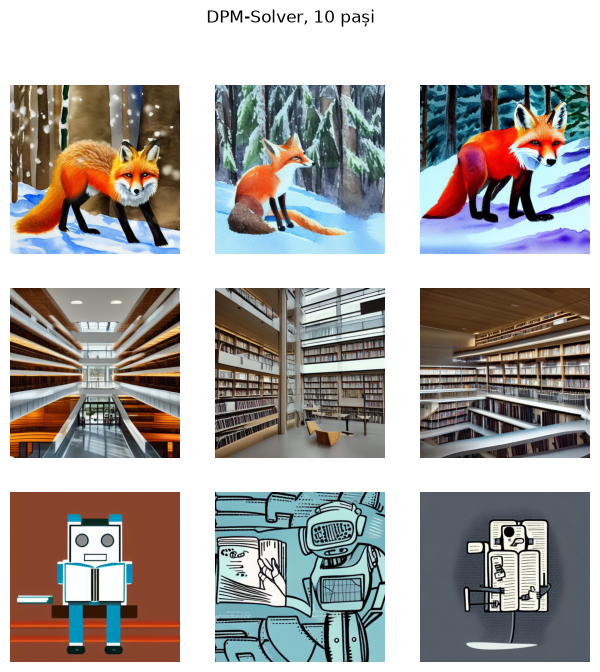

C DPM-Solver 30 pași: clip 34.98 ± 1.83, timp 13.04 s / imagine


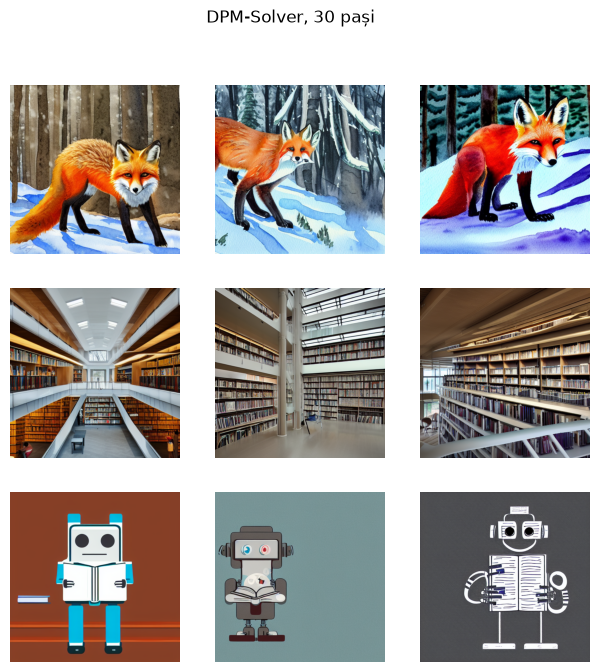

C Euler 10 pași: clip 34.15 ± 2.16, timp 4.70 s / imagine


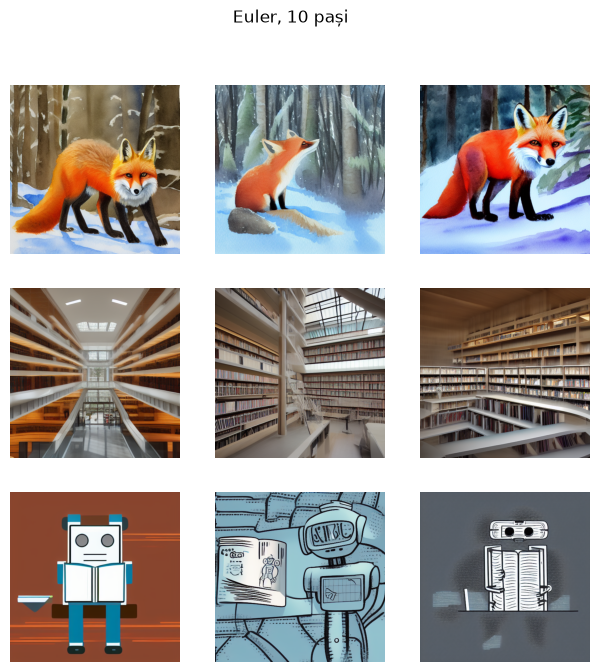

C Euler 30 pași: clip 35.58 ± 1.54, timp 13.15 s / imagine


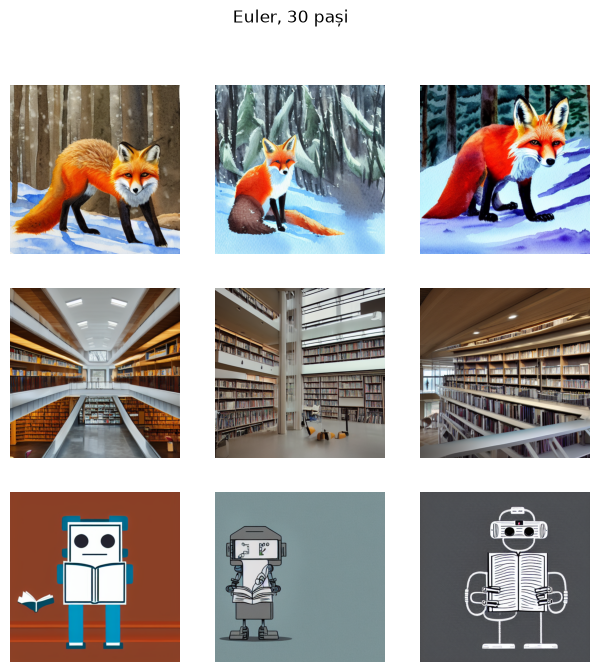

In [13]:
samplers = {"DDIM": DDIMScheduler, "DPM-Solver": DPMSolverMultistepScheduler,
            "Euler": EulerDiscreteScheduler}
for name, cls in samplers.items():
    for n in [10, 30]:
        r = ruleaza({"scheduler": cls, "steps": n})
        report(f"C {name} {n} pași", r)
        show(r["imgs"], 3, f"{name}, {n} pași")

### d. seed-ul

4 seed-uri diferite pentru primul prompt. apoi seed-ul 42 de două ori, ca să vedem dacă iese exact aceeași imagine.

D 4 seed-uri, P1: clip 36.26 ± 0.30, timp 13.67 s / imagine


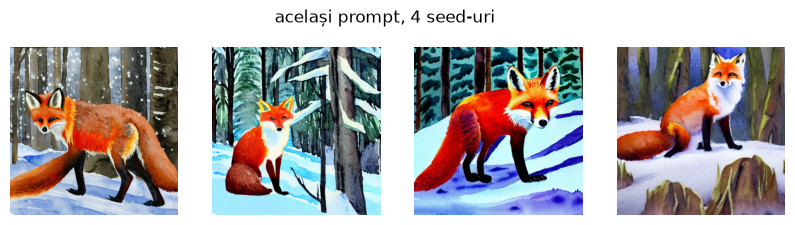

In [14]:
r = ruleaza({"prompts": PROMPTS[:1], "seeds": [42, 7, 123, 2024]})
report("D 4 seed-uri, P1", r)
show(r["imgs"], 4, "același prompt, 4 seed-uri")

In [15]:
a = np.array(generate(BASE, PROMPTS[0], 42)).astype(float)
b = np.array(generate(BASE, PROMPTS[0], 42)).astype(float)
print("diferența medie între pixeli, seed 42 de două ori:", np.abs(a - b).mean())

diferența medie între pixeli, seed 42 de două ori: 0.0


### e. promptul negativ

promptul negativ spune ce nu vrem să apară în imagine.

E cu prompt negativ: clip 34.36 ± 2.29, timp 13.67 s / imagine


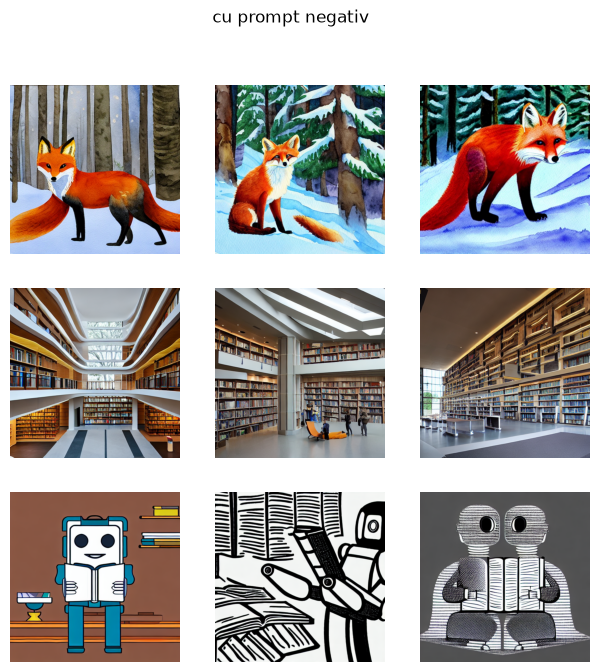

fără prompt negativ este configurația de bază:
E fără prompt negativ: clip 34.60 ± 1.56, timp 13.60 s / imagine


In [16]:
r = ruleaza({"negative": "blurry, low quality, text, watermark"})
report("E cu prompt negativ", r)
show(r["imgs"], 3, "cu prompt negativ")
print("fără prompt negativ este configurația de bază:")
report("E fără prompt negativ", base)

### opțional. img2img

pornim de la o imagine de bază și îi adăugăm zgomot. `strength` spune cât zgomot punem. este exact procesul direct din lab 4: cu strength mare ajungem aproape de zgomot pur, deci modelul desenează aproape totul din nou.

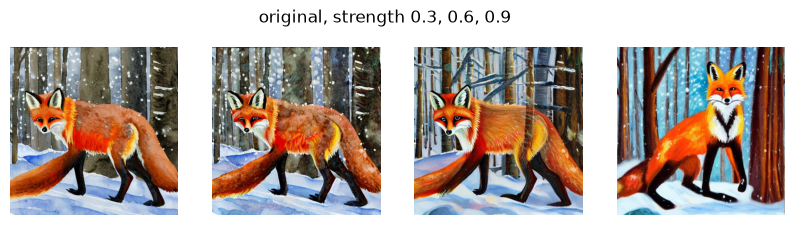

In [17]:
img2img = StableDiffusionImg2ImgPipeline(**pipe.components)
img2img.set_progress_bar_config(disable=True)
start_img = base["imgs"][0]
prompt = "an oil painting of a red fox in a snowy forest"

outs = [start_img]
for s in [0.3, 0.6, 0.9]:
    g = torch.Generator("cuda").manual_seed(42)
    outs.append(img2img(prompt, image=start_img, strength=s, guidance_scale=7.5,
                        num_inference_steps=30, generator=g).images[0])
show(outs, 4, "original, strength 0.3, 0.6, 0.9")

### toate rezultatele

In [18]:
for name, r in all_results.items():
    print(f"{name}: clip {r['clip']:.2f} ± {r['std']:.2f}, timp {r['time']:.2f} s")

bază: clip 34.60 ± 1.56, timp 13.60 s
A ghidare 1: clip 26.86 ± 5.31, timp 7.77 s
A ghidare 3: clip 34.29 ± 2.48, timp 13.65 s
A ghidare 7.5: clip 34.60 ± 1.56, timp 13.52 s
A ghidare 12: clip 34.16 ± 1.74, timp 13.51 s
A ghidare 20: clip 33.19 ± 3.40, timp 13.50 s
B 5 pași: clip 29.81 ± 6.98, timp 3.02 s
B 10 pași: clip 31.19 ± 5.70, timp 5.11 s
B 20 pași: clip 34.84 ± 1.78, timp 9.31 s
B 50 pași: clip 34.43 ± 1.73, timp 21.90 s
C DDIM 10 pași: clip 34.24 ± 1.87, timp 4.69 s
C DDIM 30 pași: clip 35.03 ± 2.03, timp 13.07 s
C DPM-Solver 10 pași: clip 34.96 ± 1.86, timp 4.65 s
C DPM-Solver 30 pași: clip 34.98 ± 1.83, timp 13.04 s
C Euler 10 pași: clip 34.15 ± 2.16, timp 4.70 s
C Euler 30 pași: clip 35.58 ± 1.54, timp 13.15 s
D 4 seed-uri, P1: clip 36.26 ± 0.30, timp 13.67 s
E cu prompt negativ: clip 34.36 ± 2.29, timp 13.67 s
E fără prompt negativ: clip 34.60 ± 1.56, timp 13.60 s


observațiile mele:

* timpii sunt măsurați pe un gpu de laptop rtx 3050 cu 4 gb, cu attention slicing. pe un t4 din colab ar fi mai mici, dar raportul dintre configurații rămâne la fel.
* bază (30 pași, ghidare 7.5): clip 34.60 ± 1.56, 13.6 s pe imagine. toate cele 9 imagini se potrivesc cu promptul: vulpea în acuarelă, biblioteca modernă, robotul care citește.
* la ghidare 1 și la 5 sau 10 pași filtrul de siguranță al modelului a crezut greșit că unele imagini sunt nsfw și le-a înlocuit cu imagini negre. o imagine neagră are un scor clip foarte mic, de aceea la aceste configurații media scade și abaterea standard crește mult (de exemplu ± 6.98 la 5 pași). este tot un semn de calitate slabă: imaginile zgomotoase păcălesc filtrul.
* ghidare 1: clip 26.86 ± 5.31. imaginile sunt haotice, vulpea abia se vede. timpul este doar 7.8 s, pentru că la ghidare 1 modelul nu mai calculează varianta fără prompt.
* ghidare 3, 7.5 și 12: clip între 34.16 și 34.60. diferențele sunt mai mici decât abaterea standard, deci nu sunt concludente.
* ghidare 20: clip 33.19 ± 3.40. culorile sunt prea saturate, iar un robot nu mai citește, ține o inimă.
* 5 pași: imagini neclare și pătate. 10 pași: mai bine, dar încă cu defecte. 20 de pași: clip 34.84, la fel de bun ca 30 sau 50 de pași.
* 50 de pași: clip 34.43, dar durează 21.9 s, de 2.4 ori mai mult decât 20 de pași, fără câștig vizibil.
* metodele de eșantionare la 10 pași: dpm-solver 34.96, ddim 34.24, euler 34.15. la 10 pași dpm-solver și euler dau imagini curate, aproape ca la 30 de pași. ddim la 10 pași este puțin mai neclar.
* la 30 de pași: euler 35.58, dpm-solver 34.98, ddim 35.03. toate diferențele sunt sub abaterea standard.
* seed: cele 4 seed-uri pentru p1 dau 4 vulpi diferite, toate bune (clip 36.26 ± 0.30). seed 42 de două ori: diferența medie între pixeli este 0.0, deci imaginile sunt identice.
* prompt negativ: 34.36 ± 2.29 față de 34.60 ± 1.56 fără. diferența nu este concludentă. vizual, la biblioteci imaginile sunt puțin mai curate.
* img2img: la strength 0.3 imaginea aproape nu se schimbă, la 0.6 se schimbă stilul și detaliile, la 0.9 apare o vulpe nouă, cu altă poză.

## sarcina 4. recomandarea

**calitate maximă:** euler, 30 de pași, ghidare 7.5, cu prompt negativ. euler la 30 de pași a avut cel mai mare scor clip (35.58 ± 1.54) și imagini curate. mai mulți pași nu ajută: la 50 de pași scorul a fost 34.43 și timpul de 21.9 s. ghidarea 7.5 este la mijloc: la 1 imaginile sunt haotice, la 20 culorile sunt prea tari și conținutul se strică. promptul negativ nu a schimbat clar scorul, dar nu costă timp și curăță puțin imaginile.

**viteză:** dpm-solver, 10 pași, ghidare 7.5. la 10 pași a dat 34.96 ± 1.86, practic la fel ca baza (34.60), dar în 4.65 s în loc de 13.6 s, adică de aproape 3 ori mai repede. pe gpu-ul meu de laptop nu se ajunge sub 2 secunde. pe un gpu mai bun (t4 sau mai puternic, fără attention slicing) 10 pași de dpm-solver ar intra în 2 secunde. dacă tot nu ajunge, putem scădea rezoluția sau folosi un model distilat, făcut pentru 1 până la 4 pași.

## întrebări de control

**1. ce se întâmplă cu imaginea la ghidare 1 și la ghidare 20? de ce?**

la ghidare 1 imaginile sunt haotice: forme amestecate, culori ciudate, vulpea abia se recunoaște. scorul clip scade la 26.86. la ghidare 1 modelul nu folosește aproape deloc promptul, generează ceva "în general". la ghidare 20 imaginile sunt prea contrastate, cu culori arse, iar unele detalii din prompt se pierd (un robot nu mai citește). scorul scade la 33.19. ghidarea împinge tare spre prompt, iar la valori mari împinge prea tare și imaginea iese din zona imaginilor naturale.

**2. de la câți pași nu mai vedeți îmbunătățiri clare? coincide cu scorul clip?**

după 20 de pași nu mai văd îmbunătățiri clare. scorul clip spune același lucru: 34.84 la 20 de pași, 34.60 la 30 și 34.43 la 50. diferențele dintre ele sunt mai mici decât abaterea standard (aproximativ 1.7). la 5 și la 10 pași scorul este clar mai mic (29.81 și 31.19).

**3. de ce metodele dpm-solver și euler se descurcă mai bine la puțini pași decât ddpm-ul din lab 4?**

ddpm face pași mici și la fiecare pas adaugă zgomot nou, de aceea are nevoie de sute de pași. dpm-solver și euler văd generarea ca pe o ecuație pe care o rezolvă numeric. ele fac pași mari și folosesc mai bine informația de la pașii anteriori (dpm-solver chiar ține minte pașii trecuți). așa ajung la o imagine bună din 20 sau 30 de pași.

**4. de ce același seed dă aceeași imagine? la ce folosește asta în practică?**

seed-ul fixează zgomotul de pornire. dacă zgomotul, promptul și setările sunt aceleași, toate calculele sunt aceleași, deci iese aceeași imagine. la noi, seed-ul 42 folosit de două ori a dat o diferență medie între pixeli de 0.0, adică imagini identice. în practică ne ajută să repetăm un rezultat, să comparăm corect setările și să modificăm doar promptul pentru o imagine care ne-a plăcut.

**5. ce nu măsoară scorul clip? dați un exemplu din imaginile voastre.**

scorul clip măsoară doar dacă imaginea și textul vorbesc despre același lucru. nu măsoară calitatea imaginii, defectele, numărul corect de obiecte sau dacă imaginea arată frumos. exemple din imaginile mele: la ghidare 20 culorile sunt arse, dar scorul a rămas 33.19, aproape ca la bază. la promptul negativ, imaginea a treia are doi roboți în loc de unul, iar clip nu observă asta. la 50 și la 20 de pași scorul este practic același, deși timpul este dublu.

**6. ce riscuri etice sau juridice vedeți în folosirea unor astfel de modele într-o companie?**

* drepturile de autor: modelul a învățat din imagini de pe internet, iar unele rezultate pot semăna cu opere protejate
* licența modelului trebuie respectată
* se pot face imagini false cu persoane reale sau imagini care induc în eroare
* modelul poate repeta stereotipuri din datele de antrenare
* clienții trebuie să știe că imaginea este generată de ai